
# RQ1 Walkthrough — The Evaluated Winning Retrieval Pipeline

This notebook is a **qualitative companion** to the quantitative RQ1 evaluation in `05_rq1_chunking_evaluation.ipynb`. Its purpose is not to re-run the full 54-configuration experiment, but to make the selected retrieval pipeline transparent and easy to inspect.

The walkthrough is organised around one concrete question-company pair and follows the same retrieval stages that produced the RQ1 winner. It therefore shows:

1. Which configuration won RQ1 under the predefined primary metric.
2. Which gold evidence passages the system should retrieve for the selected sample.
3. How the winning chunking strategy segments the report.
4. How retrieval evolves from `dense` to `sparse`, `hybrid_rrf`, and finally `hybrid_rerank`.
5. How this sample relates to the broader `Recall@15` versus `Budgeted Recall@4096` trade-off discussed in RQ1.

> **Important thesis caveat:** this notebook illustrates *how* the chosen pipeline behaves on one sample. The statistical justification for the final RQ1 conclusion remains in the full 54-configuration notebook.



## 1. Corpus Context and RQ1 Winner

Before inspecting a single example, we load the persisted RQ1 artifacts and verify that they match the current pipeline fingerprint. We then display the **primary winner** (selected by `Recall@15`) and the **budget-normalized winner** (selected by `Budgeted Recall@4096`).

This is important for interpretation: the walkthrough centers the primary winner because RQ2 and RQ3 inherit the pipeline selected by the predeclared primary metric, while still acknowledging the budget-normalized trade-off.


In [1]:

# ---------------------------------------------------------------------------
# Imports, paths, plotting defaults, and RQ1 artifact context
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
import json
import hashlib
import mmap
import re
from textwrap import shorten

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from rag.config.settings import PipelineConfig, RQ1_RESULTS_DIR, RQ1_RESULTS_VERSION
from rag.data.loaders import load_reports, load_golden_samples
from rag.data.text_utils import normalize_text
from rag.chunking.strategies import build_chunks_for_config
from rag.retrieval.methods import Retriever
from rag.evaluation.metrics import _compute_for_sample, _is_relevant

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

results_csv = RQ1_RESULTS_DIR / "rq1_config_results.csv"
winner_json = RQ1_RESULTS_DIR / "rq1_winner.json"

df = pd.read_csv(results_csv)
winner_payload = json.loads(winner_json.read_text(encoding="utf-8"))

assert len(df) == 54, f"Expected 54 configurations, found {len(df)}"
assert set(df["results_version"].dropna().astype(str)) == {RQ1_RESULTS_VERSION}, (
    "Persisted RQ1 results do not match the current pipeline fingerprint. "
    "Re-run RQ1 before interpreting this notebook."
)

rank_primary = df.sort_values("recall@15", ascending=False).reset_index(drop=True)
rank_budget = df.sort_values("budgeted_recall@4096", ascending=False).reset_index(drop=True)
primary_winner = rank_primary.iloc[0]
budget_winner = rank_budget.iloc[0]

summary_df = pd.DataFrame([
    {
        "Selection": "Primary metric winner",
        "Config": primary_winner["config_id"],
        "Recall@15": round(primary_winner["recall@15"], 4),
        "Precision@15": round(primary_winner["precision@15"], 4),
        "MRR@10": round(primary_winner["mrr@10"], 4),
        "Budgeted Recall@4096": round(primary_winner["budgeted_recall@4096"], 4),
    },
    {
        "Selection": "Budget-normalized winner",
        "Config": budget_winner["config_id"],
        "Recall@15": round(budget_winner["recall@15"], 4),
        "Precision@15": round(budget_winner["precision@15"], 4),
        "MRR@10": round(budget_winner["mrr@10"], 4),
        "Budgeted Recall@4096": round(budget_winner["budgeted_recall@4096"], 4),
    },
])

print(f"Project root        : {PROJECT_ROOT}")
print(f"Results version     : {RQ1_RESULTS_VERSION}")
print(f"Primary RQ1 winner  : {winner_payload['config_id']}")
print(f"Budget winner       : {budget_winner['config_id']}")
display(summary_df)


Project root        : /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot
Results version     : index=418550d6ec;eval=d75089ff78;rerank=3c7223536f
Primary RQ1 winner  : fixed_1024_hybrid_rerank
Budget winner       : structure_aware_512_hybrid_rrf


,Selection,Config,Recall@15,Precision@15,MRR@10,Budgeted Recall@4096
0,Primary metric winner,fixed_1024_hybrid_rerank,0.9620,0.3173,0.7961,0.7757
1,Budget-normalized winner,structure_aware_512_hybrid_rrf,0.8962,0.2307,0.7403,0.8354



## 2. Sample Selection and Gold Evidence

The walkthrough uses **Petrom / Q1 / ESRS 1**. This is a strong explanatory sample for three reasons:

- it is a **best-case sample** under the primary winner (`fixed_1024_hybrid_rerank`),
- the question is conceptually central to ESRS reporting because it concerns the **double materiality assessment**,
- the gold evidence is concentrated in a compact page range, which makes the ranking behavior easy to follow.

The table below shows the exact evidence passages that retrieval is expected to surface.


In [2]:

# ---------------------------------------------------------------------------
# Load reports and golden samples, then select the walkthrough sample.
# ---------------------------------------------------------------------------
reports = load_reports()
samples = load_golden_samples()

SAMPLE_COMPANY = "Petrom"
SAMPLE_QUESTION_ID = "Q1"
SAMPLE = next(s for s in samples if s.company == SAMPLE_COMPANY and s.question_id == SAMPLE_QUESTION_ID)

assert SAMPLE.esrs_standard == "ESRS 1"
assert len(SAMPLE.evidences) == 3, f"Expected 3 gold evidences, found {len(SAMPLE.evidences)}"

winner_details = json.loads((RQ1_RESULTS_DIR / "config_details" / f"{winner_payload['config_id']}.json").read_text())
budget_details = json.loads((RQ1_RESULTS_DIR / "config_details" / f"{budget_winner['config_id']}.json").read_text())

winner_sample_metrics = next(
    row for row in winner_details["details"]["per_sample_metrics"]
    if row["company"] == SAMPLE_COMPANY and row["question_id"] == SAMPLE_QUESTION_ID
)
budget_sample_metrics = next(
    row for row in budget_details["details"]["per_sample_metrics"]
    if row["company"] == SAMPLE_COMPANY and row["question_id"] == SAMPLE_QUESTION_ID
)

print(f"Company       : {SAMPLE.company}")
print(f"Question ID   : {SAMPLE.question_id}")
print(f"ESRS standard : {SAMPLE.esrs_standard}")
print(f"Question      : {SAMPLE.question}")

gold_df = pd.DataFrame([
    {
        "passage_id": ev.passage_id,
        "page": ev.page_number,
        "section_header": ev.source_section_header,
        "gold_preview": shorten(ev.text.replace("\n", " "), width=240, placeholder="..."),
    }
    for ev in SAMPLE.evidences
])

gold_df


Company       : Petrom
Question ID   : Q1
ESRS standard : ESRS 1
Question      : How has the undertaking conducted its double materiality assessment, and which sustainability matters were identified as material from both an impact and a financial perspective?


,passage_id,page,section_header,gold_preview
0,PETROM_Q1_E1,95,DR IRO-1 Description of the processes to ident...,The Double Materiality Assessment was conducte...
1,PETROM_Q1_E2,95-96,DR IRO-1 Description of the processes to ident...,The impacts were assessed throughout the compa...
2,PETROM_Q1_E3,94,"Material impacts, risks and opportunities and ...",[ESRS 2-SBM-3.48h] Refer to the topical chapte...



## 3. Notebook-Local Helpers for Faithful Reconstruction

The full RQ1 experiment indexed embeddings in Qdrant and cached them to disk. For this notebook, we reconstruct the same dense stage directly from the **persisted OpenAI embedding cache** for the selected sample.

This keeps the walkthrough reproducible in an offline environment while preserving the same inputs that the evaluated pipeline used:

- the same `retrieval_text` representation,
- the same cached OpenAI vectors,
- the same BM25, RRF, and reranking logic from `rag.retrieval.methods`.

A deliberate safeguard is included: if a required embedding is missing from the cache and no live API key is available, the notebook **fails clearly** rather than silently switching to the hash-based fallback embedding.


In [3]:

# ---------------------------------------------------------------------------
# Notebook-local helpers: config parsing, cache-backed embeddings,
# in-memory dense index, hit annotation, and sample metric helpers.
# ---------------------------------------------------------------------------
EMBEDDING_CACHE_PATH = PROJECT_ROOT / "data" / "artifacts" / "embedding_cache.json"
MODEL_NAME = "text-embedding-3-large"
_PAGE_RE = re.compile(r"<!--\s*Report Page\s+\d+\s*-->")
REPORT_TEXT_BY_COMPANY = {
    SAMPLE_COMPANY: normalize_text(_PAGE_RE.sub("", reports[SAMPLE_COMPANY].raw_text))
}


def parse_config_id(config_id: str) -> PipelineConfig:
    parts = config_id.split("_")
    strategy = parts[0] if parts[0] != "structure" else "structure_aware"
    if strategy == "structure_aware":
        size = int(parts[2])
        method = "_".join(parts[3:])
    else:
        size = int(parts[1])
        method = "_".join(parts[2:])
    return PipelineConfig(chunk_strategy=strategy, chunk_size=size, retrieval_method=method)


def embedding_cache_key(text: str, model: str = MODEL_NAME) -> str:
    return hashlib.sha1(f"{model}:{text}".encode("utf-8")).hexdigest()


def _extract_json_array(mm: mmap.mmap, start: int) -> list[float]:
    depth = 0
    end = start
    while end < mm.size():
        b = mm[end:end + 1]
        if b == b"[":
            depth += 1
        elif b == b"]":
            depth -= 1
            if depth == 0:
                end += 1
                break
        end += 1
    return json.loads(mm[start:end].decode("utf-8"))


def extract_vector_from_cache(text: str) -> list[float]:
    sha = embedding_cache_key(text)
    needle = f'"{sha}":'.encode("utf-8")
    with EMBEDDING_CACHE_PATH.open("rb") as f:
        mm = mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ)
        pos = mm.find(needle)
        if pos < 0:
            mm.close()
            raise RuntimeError(
                "Required embedding is missing from embedding_cache.json and no live API fallback is allowed in this notebook."
            )
        start = mm.find(b"[", pos)
        vec = _extract_json_array(mm, start)
        mm.close()
        return vec


def extract_vectors_in_order(texts: list[str]) -> list[list[float]]:
    wanted = [embedding_cache_key(text) for text in texts]
    found: dict[str, list[float]] = {}
    with EMBEDDING_CACHE_PATH.open("rb") as f:
        mm = mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ)
        pos = 0
        for sha in wanted:
            needle = f'"{sha}":'.encode("utf-8")
            found_pos = mm.find(needle, pos)
            if found_pos < 0:
                found_pos = mm.find(needle, 0)
            if found_pos < 0:
                mm.close()
                raise RuntimeError(
                    "One or more chunk embeddings are missing from embedding_cache.json. "
                    "This notebook does not permit silent fallback embeddings."
                )
            start = mm.find(b"[", found_pos)
            found[sha] = _extract_json_array(mm, start)
            pos = found_pos + 1
        mm.close()
    return [found[sha] for sha in wanted]


class CacheOnlyEmbedder:
    """Return only persisted OpenAI embeddings; never fall back silently."""

    def __init__(self, model: str = MODEL_NAME, dims: int = 3072) -> None:
        self.model = model
        self.dims = dims

    def embed_text(self, text: str) -> list[float]:
        return extract_vector_from_cache(text)


class InMemoryDenseIndex:
    """Cosine search over cached chunk vectors for one notebook sample.

    The full RQ1 experiment stored the same vectors in Qdrant. For this
    walkthrough we reconstruct dense search directly from the persisted
    vectors for the selected report, which keeps the notebook portable and
    deterministic without changing the underlying retrieval signal.
    """

    def __init__(self, chunks, vectors) -> None:
        self.chunk_ids = [c.chunk_id for c in chunks]
        arr = np.asarray(vectors, dtype=np.float64)
        norms = np.linalg.norm(arr, axis=1, keepdims=True)
        norms[norms == 0] = 1.0
        self.vectors = arr / norms

    @staticmethod
    def collection_name(strategy: str, size: int) -> str:
        return f"in_memory_{strategy}_{size}"

    def search(self, collection_name: str, query_vector: list[float], top_k: int, company: str | None = None):
        query = np.asarray(query_vector, dtype=np.float64)
        q_norm = np.linalg.norm(query) or 1.0
        scores = self.vectors @ (query / q_norm)
        order = np.argsort(-scores)[:top_k]
        return [(self.chunk_ids[i], float(scores[i]), {}) for i in order]


def sample_metrics_from_hits(hits: list) -> dict[str, float]:
    return _compute_for_sample(
        hits,
        SAMPLE,
        REPORT_TEXT_BY_COMPANY,
        chunk_span_cache={},
        gold_span_cache={},
    )


def matched_evidence_ids(chunk) -> list[str]:
    matched = []
    for ev in SAMPLE.evidences:
        if _is_relevant(
            chunk,
            ev,
            REPORT_TEXT_BY_COMPANY,
            chunk_span_cache={},
            gold_span_cache={},
        ):
            matched.append(ev.passage_id)
    return matched


def hits_to_df(hits: list, method_label: str, top_n: int = 8) -> pd.DataFrame:
    rows = []
    for hit in hits[:top_n]:
        matched = matched_evidence_ids(hit.chunk)
        rows.append({
            "method": method_label,
            "rank": hit.rank,
            "pages": f"{hit.chunk.page_start}-{hit.chunk.page_end}",
            "tokens": hit.chunk.token_count,
            "matched_gold": ", ".join(matched) if matched else "",
            "score": round(float(hit.score), 4),
            "text_preview": shorten(hit.chunk.text.replace("\n", " "), width=220, placeholder="..."),
        })
    return pd.DataFrame(rows)


def coverage_table(method_to_hits: dict[str, list]) -> pd.DataFrame:
    rows = []
    for ev in SAMPLE.evidences:
        row = {
            "passage_id": ev.passage_id,
            "page": ev.page_number,
            "section_header": ev.source_section_header,
        }
        for method, hits in method_to_hits.items():
            first_rank = None
            for hit in hits:
                if ev.passage_id in matched_evidence_ids(hit.chunk):
                    first_rank = hit.rank
                    break
            row[method] = first_rank if first_rank is not None else "not in top-15"
        rows.append(row)
    return pd.DataFrame(rows)


def config_metrics_from_artifact(config_id: str) -> dict[str, float]:
    payload = json.loads((RQ1_RESULTS_DIR / "config_details" / f"{config_id}.json").read_text())
    return next(
        row for row in payload["details"]["per_sample_metrics"]
        if row["company"] == SAMPLE_COMPANY and row["question_id"] == SAMPLE_QUESTION_ID
    )


## 4. Chunking Behavior of the Winning Pipeline

The winning RQ1 pipeline uses **fixed-size chunking with a 1024-token ceiling**. This section answers two practical questions before retrieval begins:

1. How large is the selected report under the winning chunking scheme?
2. Which chunk windows surround the **gold evidence page range** for this sample?

For readability, the preview below is selected by **page-span overlap with the gold evidence pages (94-96)** rather than by the full relevance matcher. That keeps the chunking illustration intuitive and avoids mixing in distant token-overlap matches that are more useful for evaluation diagnostics than for narrative explanation.


In [4]:

# ---------------------------------------------------------------------------
# Build winner and budget-winner chunks for the selected report.
# ---------------------------------------------------------------------------
WINNER_CONFIG = parse_config_id(winner_payload["config_id"])
BUDGET_CONFIG = parse_config_id(budget_winner["config_id"])

winner_chunks, winner_stats = build_chunks_for_config({SAMPLE_COMPANY: reports[SAMPLE_COMPANY]}, WINNER_CONFIG)
budget_chunks, budget_stats = build_chunks_for_config({SAMPLE_COMPANY: reports[SAMPLE_COMPANY]}, BUDGET_CONFIG)

chunk_compare_df = pd.DataFrame([
    {
        "Configuration": winner_payload["config_id"],
        "Strategy": WINNER_CONFIG.chunk_strategy,
        "Chunk size": WINNER_CONFIG.chunk_size,
        "Total chunks (Petrom only)": winner_stats.total_chunks,
        "Mean tokens": round(winner_stats.mean_tokens, 1),
        "Median tokens": round(winner_stats.median_tokens, 1),
        "Max tokens": winner_stats.max_tokens,
    },
    {
        "Configuration": budget_winner["config_id"],
        "Strategy": BUDGET_CONFIG.chunk_strategy,
        "Chunk size": BUDGET_CONFIG.chunk_size,
        "Total chunks (Petrom only)": budget_stats.total_chunks,
        "Mean tokens": round(budget_stats.mean_tokens, 1),
        "Median tokens": round(budget_stats.median_tokens, 1),
        "Max tokens": budget_stats.max_tokens,
    },
])

def parse_page_span(page_value: str) -> set[int]:
    pages = set()
    for part in str(page_value).split(","):
        part = part.strip()
        if not part:
            continue
        if "-" in part:
            start, end = part.split("-", 1)
            pages.update(range(int(start), int(end) + 1))
        else:
            pages.add(int(part))
    return pages

gold_pages = sorted(set().union(*[parse_page_span(ev.page_number) for ev in SAMPLE.evidences]))

def chunks_near_gold_pages(chunks: list) -> pd.DataFrame:
    rows = []
    for chunk in chunks:
        if chunk.page_start is None or chunk.page_end is None:
            continue
        chunk_pages = set(range(chunk.page_start, chunk.page_end + 1))
        overlap = sorted(chunk_pages & set(gold_pages))
        if not overlap:
            continue
        rows.append({
            "chunk_id": chunk.chunk_id[:12],
            "pages": f"{chunk.page_start}-{chunk.page_end}",
            "tokens": chunk.token_count,
            "gold_pages_intersected": ", ".join(map(str, overlap)),
            "matched_gold": ", ".join(matched_evidence_ids(chunk)) if matched_evidence_ids(chunk) else "",
            "headers": " > ".join(chunk.header_hierarchy) if chunk.header_hierarchy else "(not applicable for fixed chunking)",
            "text_preview": shorten(chunk.text.replace("\n", " "), width=220, placeholder="..."),
        })
    return pd.DataFrame(rows)

print("Chunk statistics for the selected report:")
display(chunk_compare_df)
print(f"\nGold evidence pages for the sample: {gold_pages}")
print("Winner chunks whose page spans intersect the gold evidence pages:")
display(chunks_near_gold_pages(winner_chunks).head(6))


Chunk statistics for the selected report:


,Configuration,Strategy,Chunk size,Total chunks (Petrom only),Mean tokens,Median tokens,Max tokens
0,fixed_1024_hybrid_rerank,fixed,1024,215,1022.2,1024,1026
1,structure_aware_512_hybrid_rrf,structure_aware,512,516,405.2,511,514



Gold evidence pages for the sample: [94, 95, 96]
Winner chunks whose page spans intersect the gold evidence pages:


,chunk_id,pages,tokens,gold_pages_intersected,matched_gold,headers,text_preview
0,c49199dfe4c7,93-94,1024,94,"PETROM_Q1_E1, PETROM_Q1_E2",(not applicable for fixed chunking),minimum human and labour rights for upstream v...
1,4ad947e33f3a,94-96,1024,"94, 95, 96","PETROM_Q1_E1, PETROM_Q1_E2, PETROM_Q1_E3",(not applicable for fixed chunking),and business model is crucial in addressing ma...
2,6b89724c9693,95-96,1024,"95, 96","PETROM_Q1_E1, PETROM_Q1_E2",(not applicable for fixed chunking),prior state) and Likelihood (for potential imp...
3,d2cbb9430802,96-97,1024,96,"PETROM_Q1_E1, PETROM_Q1_E2",(not applicable for fixed chunking),"Materiality Assessment, in accordance with ESR..."



## 5. Stage-by-Stage Retrieval in the Winning Pipeline

RQ1 selected `fixed_1024_hybrid_rerank`. This final pipeline is built incrementally:

1. `dense` retrieves semantically similar chunks from the cached embedding space.
2. `sparse` retrieves chunks with strong lexical overlap under BM25.
3. `hybrid_rrf` fuses both rankings with Reciprocal Rank Fusion.
4. `hybrid_rerank` applies the cross-encoder to the fused candidate set.

The code below reconstructs the winner’s chunk embeddings from the persisted embedding cache, runs all four stages on the same sample, and computes the resulting sample-level metrics.


In [5]:

# ---------------------------------------------------------------------------
# Reconstruct the winning retrieval pipeline from cached embeddings.
# ---------------------------------------------------------------------------
winner_chunk_vectors = extract_vectors_in_order([chunk.retrieval_text for chunk in winner_chunks])
cache_embedder = CacheOnlyEmbedder()
dense_index = InMemoryDenseIndex(winner_chunks, winner_chunk_vectors)

method_order = ["dense", "sparse", "hybrid_rrf", "hybrid_rerank"]
method_to_hits = {}
method_metric_rows = []

for method in method_order:
    cfg = PipelineConfig(
        chunk_strategy=WINNER_CONFIG.chunk_strategy,
        chunk_size=WINNER_CONFIG.chunk_size,
        retrieval_method=method,
        top_k=15,
    )
    retriever = Retriever(
        chunks=winner_chunks,
        config=cfg,
        embedder=cache_embedder,
        qdrant=dense_index,
    )
    hits = retriever.retrieve(SAMPLE.question, company=SAMPLE_COMPANY, top_k=15)
    method_to_hits[method] = hits
    metrics = sample_metrics_from_hits(hits)
    method_metric_rows.append({
        "Method": method,
        "Recall@5": round(metrics["recall@5"], 4),
        "Recall@10": round(metrics["recall@10"], 4),
        "Recall@15": round(metrics["recall@15"], 4),
        "Precision@15": round(metrics["precision@15"], 4),
        "MRR@10": round(metrics["mrr@10"], 4),
        "Budgeted Recall@4096": round(metrics["budgeted_recall@4096"], 4),
    })

method_metrics_df = pd.DataFrame(method_metric_rows)
print("Sample-level metrics for Petrom / Q1 under the winner chunking configuration:")
display(method_metrics_df)

print("Persisted artifact metrics for the final winning method on this sample:")
display(pd.DataFrame([{
    k: round(winner_sample_metrics[k], 4)
    for k in ["recall@5", "recall@10", "recall@15", "precision@15", "mrr@10", "budgeted_recall@4096"]
}]))


Sample-level metrics for Petrom / Q1 under the winner chunking configuration:


,Method,Recall@5,Recall@10,Recall@15,Precision@15,MRR@10,Budgeted Recall@4096
0,dense,1.0,1.0,1.0,0.7333,1.0,1.0
1,sparse,1.0,1.0,1.0,0.8667,1.0,1.0
2,hybrid_rrf,1.0,1.0,1.0,0.9333,1.0,1.0
3,hybrid_rerank,1.0,1.0,1.0,0.9333,1.0,1.0


Persisted artifact metrics for the final winning method on this sample:


,recall@5,recall@10,recall@15,precision@15,mrr@10,budgeted_recall@4096
0,1.0,1.0,1.0,0.9333,1.0,1.0



## 6. Retrieved Evidence and Ranking Shifts

The next outputs make the abstract metrics concrete:

- the **top retrieved chunks** show which passages each method surfaces,
- the **matched gold evidence ids** show whether those hits are genuinely relevant,
- the **coverage table** shows the first rank at which each gold evidence passage is retrieved,
- the **ranking shift plot** reveals how the same chunks move between dense, sparse, fusion, and reranking.



  DENSE


,method,rank,pages,tokens,matched_gold,score,text_preview
0,dense,1,95-96,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.6914,prior state) and Likelihood (for potential imp...
1,dense,2,96-97,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.6613,"Materiality Assessment, in accordance with ESR..."
2,dense,3,94-96,1024,"PETROM_Q1_E1, PETROM_Q1_E2, PETROM_Q1_E3",0.6000,and business model is crucial in addressing ma...
3,dense,4,97-99,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.5837,which confirms that the OMV Petrom portfolio i...
4,dense,5,98-100,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.5824,1.8b] We used the conclusions of our regular c...
5,dense,6,83-85,1023,"PETROM_Q1_E1, PETROM_Q1_E2",0.5757,we have also internally defined Sustainability...
6,dense,7,236-237,1023,,0.5707,ESRS E1-5 Energy consumption and mix paragraph...
7,dense,8,234-236,1025,,0.5656,Opportunity Management | [S3-4] | Actions | | ...



  SPARSE


,method,rank,pages,tokens,matched_gold,score,text_preview
0,sparse,1,95-96,1024,"PETROM_Q1_E1, PETROM_Q1_E2",31.8136,prior state) and Likelihood (for potential imp...
1,sparse,2,94-96,1024,"PETROM_Q1_E1, PETROM_Q1_E2, PETROM_Q1_E3",28.1329,and business model is crucial in addressing ma...
2,sparse,3,96-97,1024,"PETROM_Q1_E1, PETROM_Q1_E2",26.5671,"Materiality Assessment, in accordance with ESR..."
3,sparse,4,77-78,1023,"PETROM_Q1_E1, PETROM_Q1_E2",24.8138,## Sustainability Statement How to read this s...
4,sparse,5,78-79,1024,"PETROM_Q1_E1, PETROM_Q1_E2",24.8054,b i] The consolidation scope of the Sustainabi...
5,sparse,6,100-102,1024,PETROM_Q1_E1,24.7786,as material (E5-IRO 1 AR 7a-f are not applicab...
6,sparse,7,180-180,1024,"PETROM_Q1_E1, PETROM_Q1_E2",23.7300,V Petrom is working with Saipem that will exec...
7,sparse,8,82-83,1024,"PETROM_Q1_E1, PETROM_Q1_E2",23.2775,targets within various task-forces. The settin...



  HYBRID_RRF


,method,rank,pages,tokens,matched_gold,score,text_preview
0,hybrid_rrf,1,95-96,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.0328,prior state) and Likelihood (for potential imp...
1,hybrid_rrf,2,96-97,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.0320,"Materiality Assessment, in accordance with ESR..."
2,hybrid_rrf,3,94-96,1024,"PETROM_Q1_E1, PETROM_Q1_E2, PETROM_Q1_E3",0.0320,and business model is crucial in addressing ma...
3,hybrid_rrf,4,97-99,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.0299,which confirms that the OMV Petrom portfolio i...
4,hybrid_rrf,5,98-100,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.0299,1.8b] We used the conclusions of our regular c...
5,hybrid_rrf,6,77-78,1023,"PETROM_Q1_E1, PETROM_Q1_E2",0.0297,## Sustainability Statement How to read this s...
6,hybrid_rrf,7,100-102,1024,PETROM_Q1_E1,0.0296,as material (E5-IRO 1 AR 7a-f are not applicab...
7,hybrid_rrf,8,78-79,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.0289,b i] The consolidation scope of the Sustainabi...



  HYBRID_RERANK


,method,rank,pages,tokens,matched_gold,score,text_preview
0,hybrid_rerank,1,95-96,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.9532,prior state) and Likelihood (for potential imp...
1,hybrid_rerank,2,96-97,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.9392,"Materiality Assessment, in accordance with ESR..."
2,hybrid_rerank,3,94-96,1024,"PETROM_Q1_E1, PETROM_Q1_E2, PETROM_Q1_E3",0.9226,and business model is crucial in addressing ma...
3,hybrid_rerank,4,100-102,1024,PETROM_Q1_E1,0.8791,as material (E5-IRO 1 AR 7a-f are not applicab...
4,hybrid_rerank,5,97-99,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.8447,which confirms that the OMV Petrom portfolio i...
5,hybrid_rerank,6,77-78,1023,"PETROM_Q1_E1, PETROM_Q1_E2",0.8144,## Sustainability Statement How to read this s...
6,hybrid_rerank,7,82-83,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.7582,targets within various task-forces. The settin...
7,hybrid_rerank,8,98-100,1024,"PETROM_Q1_E1, PETROM_Q1_E2",0.7557,1.8b] We used the conclusions of our regular c...



First rank at which each gold evidence passage is retrieved:


,passage_id,page,section_header,dense,sparse,hybrid_rrf,hybrid_rerank
0,PETROM_Q1_E1,95,DR IRO-1 Description of the processes to ident...,1,1,1,1
1,PETROM_Q1_E2,95-96,DR IRO-1 Description of the processes to ident...,1,1,1,1
2,PETROM_Q1_E3,94,"Material impacts, risks and opportunities and ...",3,2,3,3


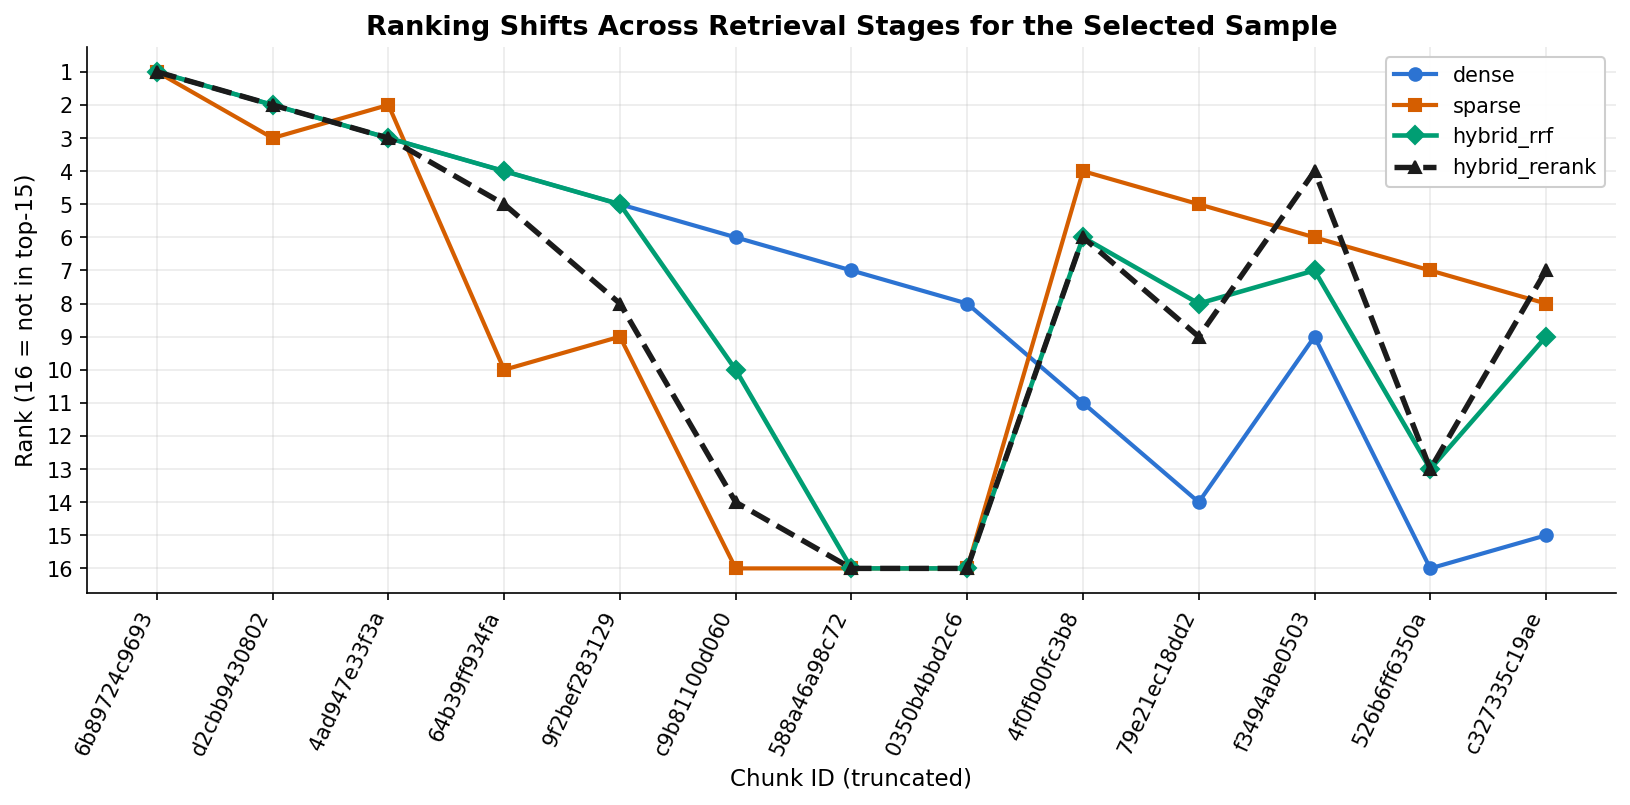

In [6]:

# ---------------------------------------------------------------------------
# Display retrieved chunks per stage and visualise rank shifts.
# ---------------------------------------------------------------------------
for method in method_order:
    print("\n" + "=" * 96)
    print(f"  {method.upper()}")
    print("=" * 96)
    display(hits_to_df(method_to_hits[method], method_label=method, top_n=8))

print("\nFirst rank at which each gold evidence passage is retrieved:")
display(coverage_table(method_to_hits))

rank_maps = {
    method: {hit.chunk.chunk_id[:12]: hit.rank for hit in hits}
    for method, hits in method_to_hits.items()
}
all_ids = sorted(set().union(*[set(rank_map) for rank_map in rank_maps.values()]))
# Focus on the union of the top-8 chunks from all stages for readability.
focus_ids = []
for method in method_order:
    focus_ids.extend([hit.chunk.chunk_id[:12] for hit in method_to_hits[method][:8]])
focus_ids = list(dict.fromkeys(focus_ids))

plot_rows = []
for cid in focus_ids:
    row = {"chunk_id": cid}
    for method in method_order:
        row[method] = rank_maps[method].get(cid, 16)
    plot_rows.append(row)
rank_plot_df = pd.DataFrame(plot_rows)

fig, ax = plt.subplots(figsize=(11, 5.5))
x = range(len(rank_plot_df))
style_map = {
    "dense": {"color": "#2C73D2", "marker": "o", "linewidth": 2},
    "sparse": {"color": "#D55E00", "marker": "s", "linewidth": 2},
    "hybrid_rrf": {"color": "#009E73", "marker": "D", "linewidth": 2.2},
    "hybrid_rerank": {"color": "#1B1B1B", "marker": "^", "linewidth": 2.6, "linestyle": "--"},
}
for method in method_order:
    ax.plot(x, rank_plot_df[method], label=method, markersize=6, **style_map[method])

ax.set_xticks(list(x))
ax.set_xticklabels(rank_plot_df["chunk_id"], rotation=65, ha="right")
ax.set_ylabel("Rank (16 = not in top-15)")
ax.set_xlabel("Chunk ID (truncated)")
ax.set_title("Ranking Shifts Across Retrieval Stages for the Selected Sample", fontweight="bold")
ax.invert_yaxis()
ax.set_yticks(range(1, 17))
ax.legend(loc="best", framealpha=0.95)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()



## 7. Compact Comparison with the Budget-Normalized Winner

RQ1 selected the final pipeline by `Recall@15`, but the budget-normalized analysis identified a different corpus-level winner: `structure_aware_512_hybrid_rrf`.

To keep the trade-off explicit, the table below compares both configurations on the same selected sample. This is a **local contrast**, not a replacement for the corpus-level robustness analysis from the main RQ1 notebook.


In [7]:

# ---------------------------------------------------------------------------
# Compare the selected sample under the primary winner and the budget winner.
# ---------------------------------------------------------------------------
budget_compare_df = pd.DataFrame([
    {
        "Configuration": winner_payload["config_id"],
        "Selection basis": "Primary metric winner",
        "Recall@15": round(winner_sample_metrics["recall@15"], 4),
        "Precision@15": round(winner_sample_metrics["precision@15"], 4),
        "MRR@10": round(winner_sample_metrics["mrr@10"], 4),
        "Budgeted Recall@4096": round(winner_sample_metrics["budgeted_recall@4096"], 4),
    },
    {
        "Configuration": budget_winner["config_id"],
        "Selection basis": "Budget-normalized winner",
        "Recall@15": round(budget_sample_metrics["recall@15"], 4),
        "Precision@15": round(budget_sample_metrics["precision@15"], 4),
        "MRR@10": round(budget_sample_metrics["mrr@10"], 4),
        "Budgeted Recall@4096": round(budget_sample_metrics["budgeted_recall@4096"], 4),
    },
])

budget_compare_df


,Configuration,Selection basis,Recall@15,Precision@15,MRR@10,Budgeted Recall@4096
0,fixed_1024_hybrid_rerank,Primary metric winner,1.0000,0.9333,1.0,1.0000
1,structure_aware_512_hybrid_rrf,Budget-normalized winner,0.6667,0.6000,0.5,0.6667



## 8. Interpretation

### What This Sample Illustrates Clearly

For `Petrom / Q1`, the primary RQ1 winner (`fixed_1024_hybrid_rerank`) retrieves **all three** gold evidence passages within the top ranks and does so with excellent sample-level precision. The sample therefore makes the winner pipeline easy to interpret: larger fixed chunks preserve the full materiality discussion, BM25 contributes exact regulatory phrasing, RRF consolidates both signals, and reranking preserves the strong fused ranking.

### Why the Budget Caveat Still Matters

This same sample favors the primary winner, but that does **not** invalidate the budget-normalized analysis. At corpus level, the RQ1 notebook showed that `structure_aware_512_hybrid_rrf` is strongest once a strict 4096-token context budget is imposed. The correct thesis interpretation is therefore:

- the final pipeline was selected by the **predeclared primary metric** (`Recall@15`),
- a different configuration is strongest under the **budget-normalized robustness metric**,
- this notebook illustrates the chosen pipeline on one clean sample, rather than proving universal dominance over all 204 samples.

### Methodological Note

This walkthrough reconstructs dense search from the persisted OpenAI embedding cache and keeps the exact `retrieval_text` representation used in RQ1. That makes the notebook faithful to the evaluated retrieval signal while remaining executable without a live embedding API call.



---

*End of walkthrough. For the full 54-configuration RQ1 evaluation, interaction heatmaps, robustness analysis, and statistical significance tests, see `05_rq1_chunking_evaluation.ipynb`.*
